# Import Libraries

In [ ]:
from qrisp.operators.qubit.operator_factors import X, Y, Z
from qrisp.algorithms.vqe.problems.heisenberg import create_heisenberg_init_function
import networkx as nx
import numpy as np
from scipy.sparse.linalg import eigsh

from run_qite import run_qite
from run_qcgd import run_qcgd
import matplotlib.pyplot as plt

# Save/Load Data functionality

In [4]:
from saveload import save_data, load_data

# Heisenberg XXX model

$$ H_{\text{TFIM}} = \sum_{j=0}^{L-1}(X_jX_{j+1}+Y_jY_{j+1}+Z_jZ_{j+1}) $$

In [2]:
def create_heisenberg_hamiltonian(G):
    H = sum(X(i)*X(j)+Y(i)*Y(j)+Z(i)*Z(j) for (i,j) in G.edges())
    return H

# Create a graph
def create_graph(N):
    G = nx.Graph()
    G.add_edges_from([(k, (k+1)%N) for k in range(N-1)]) 
    return G

def calculate_spectra(L):
    G = nx.Graph()
    G.add_edges_from([(k,(k+1)%L) for k in range(L-1)]) 

    H = create_heisenberg_hamiltonian(G)

    M = H.to_sparse_matrix()
    eigenvalues, eigenvectors = eigsh(M, k=2, which='SA')
    return eigenvalues, eigenvectors

def get_statevector(qc, n, subs_dic=None):
    if subs_dic is not None:
        bqc = qc.bind_parameters(subs_dic) 
    else:
        bqc = qc
    
    for i in range(bqc.num_qubits() - n):
        bqc.qubits.insert(0, bqc.qubits.pop(-1))

    statevector = bqc.statevector_array()[:2**n]
    statevector = statevector/np.linalg.norm(statevector)

    return statevector

# Calculate Hamiltonian Spectrum Classically

In [ ]:
try:
    E0_val, E1_val, E0_vec, E1_vec = load_data("spectra").values()

except FileNotFoundError:
    x_val = list(range(4, 22, 2))

    spectra = dict()
    for L in x_val:
        spectra[L] = calculate_spectra(L)

    E0_val = dict()
    E1_val = dict()
    E0_vec = dict()
    E1_vec = dict()

    for L in x_val:
        E0_val[L] = spectra[L][0][0]
        E1_val[L] = spectra[L][0][1]

        E0_vec[L] = spectra[L][1][:, 0]
        E1_vec[L] = spectra[L][1][:, 1]

    save_data(
        {
            "ground energies": E0_val,
            "first excited energies": E1_val,
            "E0_vec": E0_vec,
            "E1_vec": E1_vec,
        },
        "spectra",
    )

# 1st Order DB-QITE and QCGD

## Singlet Warm Start

In [ ]:
plot_results = []
r = 0.5
for N in [6,8,10,12,14,16,18,20]:
    G = create_graph(N)
    H = create_heisenberg_hamiltonian(G)

    alpha = 1
    beta = 1
    def exp_H(qv, t):
        H.trotterization(method='commuting')(qv,t * beta/alpha,5)
        
    E_tar = E0_val[N]
    print("[INFO] THIS IS THE TARGET ENERGY for ", N, "qubits:", E_tar)
    M = nx.maximal_matching(G)
    U_singlet = create_heisenberg_init_function(M)
    
    qite_results = run_qite(N, 3, H, exp_H, U_singlet, use_statevectors=True, title="singlet", mu_max=r)
    qcgd_results = run_qcgd(N, 3, H, exp_H, U_singlet, use_statevectors=True, title="singlet", param_max=r)
    

    psi = E0_vec[N] # ground state
    states = qcgd_results["statevectors"]
    fidelities = []
    for phi in states:
        fidelities.append(np.abs(np.dot(psi.conj().transpose(),phi))**2)
    
    results = [{
        "N": N,
        "E_tar": E_tar,
        "qcgd_results": qcgd_results,
        "fidelities": fidelities
    }]

    states = qite_results["statevectors"]
    fidelities = []
    for phi in states:
        fidelities.append(np.abs(np.dot(psi.conj().transpose(),phi))**2)

    results.append({
            "N": N,
            "E_tar": E_tar,
            "qite_results": qite_results,
            "fidelities": fidelities
        })

    plot_results.append({
        "N": N,
        "E_tar": E_tar,
        "qite_results": qite_results,
        "qcgd_results": qcgd_results,
    })
    
    save_data(results,'singlet', folder=[f"alpha{alpha}beta{beta}", f"resultsL={N}", f"convergence{r}"])

[INFO] THIS IS THE TARGET ENERGY for  6 qubits: -9.974308535551689
[QITE] THIS IS MIN ENERGY AFTER QITE step 1 :  -9.375886671884293               
[QITE] THIS IS MIN ENERGY AFTER QITE step 2 :  -9.614318969021365               
[QITE] THIS IS MIN ENERGY AFTER QITE step 3 :  -9.755225500770326               
[QITE] THESE ARE THE OPTIMAL ENERGIES: [np.float64(-8.999999691943124), np.float64(-9.375886671884293), np.float64(-9.614318969021365), np.float64(-9.755225500770326)]
[QITE] THESE ARE THE OPTIMAL S: [np.float64(0.2894736842105263), np.float64(0.2631578947368421), np.float64(0.23684210526315788), theta]
[QCGD] THIS IS MIN ENERGY AFTER QITE step: -9.375887193020226                   
[QCGD] THIS IS ENERGY at mu=0,gamma=0 AFTER QCGD step 2 :  -9.375886385105085   
[QCGD] THIS IS ENERGY at mu=0,gamma=random AFTER QCGD step 2 :  -9.375886350335282
[QCGD] THIS IS MIN ENERGY AFTER QCGD step 2 :  -9.787187933160709
[QCGD] THIS IS ENERGY at mu=0,gamma=0 AFTER QCGD step 3 :  -9.787183643882

## Sketch Energy Plot (optional)

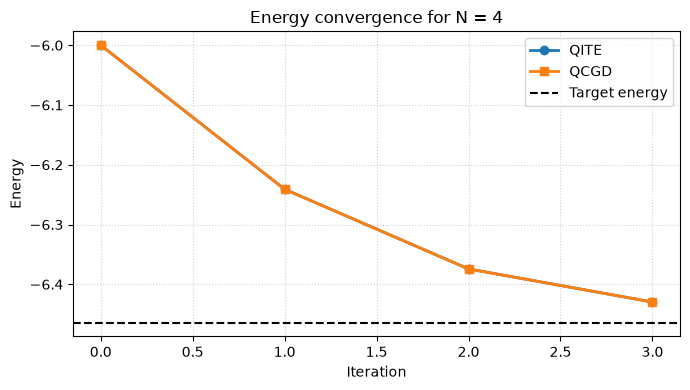

In [ ]:
# Sketch plot of energy convergence

fig, axes = plt.subplots(
    nrows=len(plot_results),
    ncols=1,
    figsize=(7, 4 * len(plot_results)),
    squeeze=False,
)
for ax, result in zip(axes.flat, plot_results):
    N = result["N"]
    E_tar = result["E_tar"]

    qite_energies = np.asarray(result["qite_results"]["energies"]).squeeze()
    qcgd_energies = np.asarray(result["qcgd_results"]["energies"]).squeeze()

    qite_steps = np.arange(len(qite_energies))
    qcgd_steps = np.arange(len(qcgd_energies))

    ax.plot(
        qite_steps,
        qite_energies,
        marker="o",
        linewidth=2,
        label="QITE",
    )
    ax.plot(
        qcgd_steps,
        qcgd_energies,
        marker="s",
        linewidth=2,
        label="QCGD",
    )
    ax.axhline(
        E_tar,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Target energy",
    )

    ax.set_title(f"Energy convergence for N = {N}")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Energy")
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend()

fig.tight_layout()
plt.show()


## $\gamma=0$ test (optional)

In [ ]:
# Test to check if DB-QITE and QCGD produce equivalent results for gamma=0

from qrisp.algorithms.vqe import VQEProblem
from qrisp import QuantumVariable

N=8
G = create_graph(N)
H = create_heisenberg_hamiltonian(G)

alpha = 1
beta = 1
def exp_H(qv, t):
    H.trotterization(method='commuting')(qv,t * beta/alpha,5)

E_tar = H.ground_state_energy()

M = nx.maximal_matching(G)
U_singlet = create_heisenberg_init_function(M)

# HVA
H0 = sum((X(i)*X(j)+Y(i)*Y(j)+Z(i)*Z(j)) for i,j in M)
H1 = sum((X(i)*X(j)+Y(i)*Y(j)+Z(i)*Z(j)) for i,j in set(G.edges())-M)

def ansatz(qv, theta):
    # Rescaling t->1/4 equivalent to choosing rescaled inital parameters for HVA
    H1.trotterization(method='commuting')(qv, t=theta[1]/4)
    H0.trotterization(method='commuting')(qv, t=theta[0]/4)

HVA = VQEProblem(H, ansatz, 2, init_function=U_singlet)
U_HVA = HVA.train_function(QuantumVariable(G.number_of_nodes()), depth=1, max_iter=100)

from qrisp import QuantumVariable
from qite import QITE
from qcgd import QCGD
import numpy as np

steps = 3

def build_qite_step(N, U_0, exp_H, M, formula="GC"):
    qv = QuantumVariable(N)

    QITE(qv, U_0, exp_H, M, steps, method=formula, alpha=1, beta=1)

    return qv, qv.qs.compile()


def build_qcgd_step_gamma_zero(N, U_0, exp_H, M,formula="GC",):
    qv = QuantumVariable(N)

    QCGD(qv,U_0,exp_H,M,[0 for _ in range(len(M)-1)], steps, method=formula,alpha=1,beta=1,)

    return qv, qv.qs.compile()

M =[0.5, 0.7, 0.2]  # same parameter values for both methods

qv_qite, qc_qite = build_qite_step(N, U_singlet, exp_H, M,)

qv_qcgd, qc_qcgd = build_qcgd_step_gamma_zero(N, U_singlet, exp_H, M,)

print("QITE circuit qubits:", qc_qite.num_qubits())
print("QCGD circuit qubits:", qc_qcgd.num_qubits())

psi_qite = get_statevector(qc_qite, N)
psi_qcgd = get_statevector(qc_qcgd, N)

overlap = np.vdot(psi_qite, psi_qcgd)
fidelity = np.abs(overlap) ** 2

print("Fidelity:", fidelity)
print("Maximum amplitude difference:", np.max(np.abs(psi_qite - psi_qcgd)))

/Users/alejarcialopez/miniforge3/envs/qrisp-env/lib/python3.11/site-packages/numpy/linalg/_linalg.py:2407: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/alejarcialopez/miniforge3/envs/qrisp-env/lib/python3.11/site-packages/numpy/linalg/_linalg.py:2407: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


ignoring reflection with c= 0                                                   
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
ignoring reflection with c= 0
QITE circuit qubits: 10
QCGD circuit qubits: 10
Fidelity: 0.99999976                                                            
Maximum amplitude difference: 3.6808295e

## HVA Warm Start

In [ ]:
from qrisp.algorithms.vqe import VQEProblem
from qrisp import QuantumVariable

r=0.5
for N in [6,8,10,12,14,16,18,20]:
    G = create_graph(N)
    H = create_heisenberg_hamiltonian(G)

    alpha = 1
    beta = 1
    def exp_H(qv, t):
        H.trotterization(method='commuting')(qv,t * beta/alpha,5)
    
    E_tar = H.ground_state_energy()

    M = nx.maximal_matching(G)
    U_singlet = create_heisenberg_init_function(M)

    # HVA
    H0 = sum((X(i)*X(j)+Y(i)*Y(j)+Z(i)*Z(j)) for i,j in M)
    H1 = sum((X(i)*X(j)+Y(i)*Y(j)+Z(i)*Z(j)) for i,j in set(G.edges())-M)

    def ansatz(qv, theta):
        # Rescaling t->1/4 equivalent to choosing rescaled inital parameters for HVA
        H1.trotterization(method='commuting')(qv, t=theta[1]/4)
        H0.trotterization(method='commuting')(qv, t=theta[0]/4)

    HVA = VQEProblem(H, ansatz, 2, init_function=U_singlet)
    U_HVA = HVA.train_function(QuantumVariable(G.number_of_nodes()), depth=1, max_iter=100)

    qite_results = run_qite(N, 3, H, exp_H, U_HVA, use_statevectors=True, title="HVA", mu_max=r)
    qcgd_results = run_qcgd(N, 3, H, exp_H, U_HVA, use_statevectors=True, title="HVA", param_max=r)

    psi = E0_vec[N] # ground state
    states = qcgd_results["statevectors"]
    fidelities = []
    for phi in states:
        fidelities.append(np.abs(np.dot(psi.conj().transpose(),phi))**2)
    
    results = [{
        "N": N,
        "E_tar": E_tar,
        "qcgd_results": qcgd_results,
        "fidelities": fidelities
    }]

    states = qite_results["statevectors"]
    fidelities = []
    for phi in states:
        fidelities.append(np.abs(np.dot(psi.conj().transpose(),phi))**2)

    results.append({
            "N": N,
            "E_tar": E_tar,
            "qite_results": qite_results,
            "fidelities": fidelities
        })
    
    save_data(results,'HVA', folder=[f"alpha{alpha}beta{beta}", f"resultsL={N}", f"convergence{r}"])

/Users/alejarcialopez/miniforge3/envs/qrisp-env/lib/python3.11/site-packages/numpy/linalg/_linalg.py:2407: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/alejarcialopez/miniforge3/envs/qrisp-env/lib/python3.11/site-packages/numpy/linalg/_linalg.py:2407: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


/Users/alejarcialopez/miniforge3/envs/qrisp-env/lib/python3.11/site-packages/numpy/linalg/_linalg.py:2407: RuntimeWarning: divide by zero encountered in det
  r = _umath_linalg.det(a, signature=signature)
/Users/alejarcialopez/miniforge3/envs/qrisp-env/lib/python3.11/site-packages/numpy/linalg/_linalg.py:2407: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


[QITE] THIS IS MIN ENERGY AFTER QITE step 1 :  -34.23816589185913               
[QITE] THIS IS MIN ENERGY AFTER QITE step 2 :  -34.324719873407766              
[QITE] THIS IS MIN ENERGY AFTER QITE step 3 :  -34.394318180356706              
[QITE] THESE ARE THE OPTIMAL ENERGIES: [np.float64(-33.78867506742221), np.float64(-34.23816589185913), np.float64(-34.324719873407766), np.float64(-34.394318180356706)]
[QITE] THESE ARE THE OPTIMAL S: [np.float64(0.631578947368421), np.float64(0.15789473684210525), np.float64(0.15789473684210525), theta]
[QCGD] THIS IS MIN ENERGY AFTER QITE step: -34.23704893811043                   
[QCGD] THIS IS ENERGY at mu=0,gamma=0 AFTER QCGD step 2 :  -34.244158622508195  
[QCGD] THIS IS ENERGY at mu=0,gamma=random AFTER QCGD step 2 :  -34.24420889348923
[QCGD] THIS IS MIN ENERGY AFTER QCGD step 2 :  -34.43049279339102
[QCGD] THIS IS ENERGY at mu=0,gamma=0 AFTER QCGD step 3 :  -34.43499935635751   
[QCGD] THIS IS ENERGY at mu=0,gamma=random AFTER QCGD step